In [27]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/kaggle/input/datasets/mylesoneill/warcraft-avatar-history/wowah_data.csv')

print("DataFrame type:", type(df))
print("DataFrame shape:", df.shape)



# Dataset dimensions
print("Dataset shape:", df.shape)

df.info()

# Preview the dataset
print(df.head())

# Check for missing values
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nUnique characters:")
print(df['char'].nunique())



# Summary statistics
print(df.describe())

DataFrame type: <class 'pandas.core.frame.DataFrame'>
DataFrame shape: (10826734, 7)
Dataset shape: (10826734, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10826734 entries, 0 to 10826733
Data columns (total 7 columns):
 #   Column      Dtype 
---  ------      ----- 
 0   char        int64 
 1    level      int64 
 2    race       object
 3    charclass  object
 4    zone       object
 5    guild      int64 
 6    timestamp  object
dtypes: int64(3), object(4)
memory usage: 578.2+ MB
    char   level  race  charclass                zone   guild  \
0  59425       1   Orc      Rogue           Orgrimmar     165   
1  65494       9   Orc     Hunter             Durotar      -1   
2  65325      14   Orc    Warrior          Ghostlands      -1   
3  65490      18   Orc     Hunter          Ghostlands      -1   
4   2288      60   Orc     Hunter  Hellfire Peninsula      -1   

           timestamp  
0  01/01/08 00:02:04  
1  01/01/08 00:02:04  
2  01/01/08 00:02:04  
3  01/01/08 00:02:04 

In [28]:

print(df.columns.tolist())


['char', ' level', ' race', ' charclass', ' zone', ' guild', ' timestamp']


In [29]:
print("Minimum level:", df[' level'].min())
print("Maximum level:", df[' level'].max())

print("\nCharacter classes:")
print(df[' charclass'].value_counts())

print("\nUnique characters:", df['char'].nunique())
print("Duplicate rows:", df.duplicated().sum())

Minimum level: 1
Maximum level: 80

Character classes:
 charclass
Hunter          1549924
Mage            1437914
Warlock         1347409
Warrior         1282538
Paladin         1158652
Priest          1127051
Rogue           1050134
Druid            916344
Shaman           726679
Death Knight     230089
Name: count, dtype: int64

Unique characters: 37354
Duplicate rows: 3557


In [30]:
df[' timestamp'] = pd.to_datetime(
    df[' timestamp'],
    format='%m/%d/%y %H:%M:%S',
    errors='coerce'
)

print("Invalid timestamps:", df[' timestamp'].isna().sum())
print("First observation:", df[' timestamp'].min())
print("Last observation:", df[' timestamp'].max())

df['date'] = df[' timestamp'].dt.date

Invalid timestamps: 0
First observation: 2008-01-01 00:02:04
Last observation: 2008-12-31 23:50:18


Unique characters: 37354

Maximum observed level summary:


count    37354.000000
mean        20.474353
std         26.133273
min          1.000000
25%          1.000000
50%          6.000000
75%         32.000000
max         80.000000
Name: max_level, dtype: float64

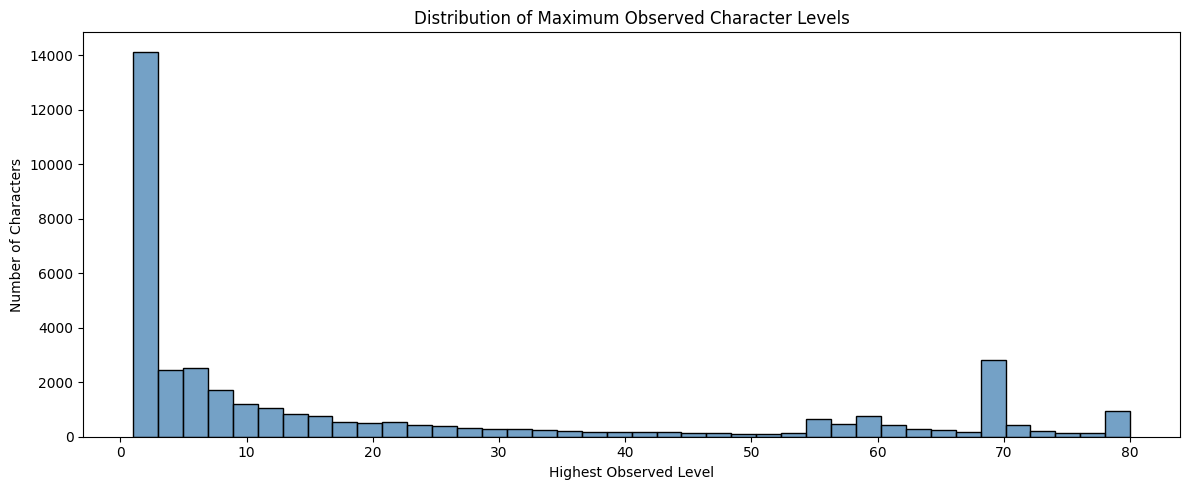

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Highest observed level for each character
character_levels = (
    df.groupby('char')[' level']
    .max()
    .reset_index(name='max_level')
)

print("Unique characters:", len(character_levels))

print("\nMaximum observed level summary:")
display(character_levels['max_level'].describe())

# Plot maximum observed level distribution
plt.figure(figsize=(12, 5))

sns.histplot(
    data=character_levels,
    x='max_level',
    bins=40,
    color='steelblue'
)

plt.title('Distribution of Maximum Observed Character Levels')
plt.xlabel('Highest Observed Level')
plt.ylabel('Number of Characters')
plt.tight_layout()
plt.show()

### Interpretation: Maximum Observed Character Levels

The analysis includes 37,354 unique characters, each represented by their highest observed level during the dataset's observation period.

The distribution is strongly right-skewed. The median maximum observed level is 6, while the mean is approximately 20.47. This indicates that many characters were observed only at relatively low levels, while a smaller group reached substantially higher levels.

The 25th percentile is level 1, suggesting that at least one-quarter of characters were never observed above level 1. Meanwhile, the 75th percentile is level 32, indicating that one-quarter reached at least approximately level 32.

The histogram also shows visible concentrations around levels 60, 70, and 80. These may be associated with historical progression milestones and level caps.

**Business Interpretation**

The results suggest substantial differences in observed character progression. However, low maximum observed levels should not automatically be interpreted as player churn or failure to progress.

Additional longitudinal analysis is needed to distinguish characters with limited observation histories from characters showing sustained progression.

The next step is to examine character-level progression patterns over time.

## Character Progression Analysis Using SQL

### Business Question

How much do characters progress between their first and last recorded observations, and how does this progression vary across the character population?

### Analytical Approach

For each character, I identify the first and last recorded observations and calculate the change in level.

I then use SQL to summarize progression patterns, including the number of characters with positive, zero, or negative observed level changes.

Because the dataset contains periodic character observations rather than complete gameplay events, these changes represent observed progression rather than exact leveling speed or time spent playing.

In [32]:
import pandas as pd
import sqlite3

# Sort observations chronologically
df_sorted = df.sort_values(
    ['char', ' timestamp']
)

# Get first and last observed record for each character
first_obs = df_sorted.groupby('char').first()
last_obs = df_sorted.groupby('char').last()

# Create progression summary
progression = pd.DataFrame({
    'char': first_obs.index,
    'first_level': first_obs[' level'].values,
    'last_level': last_obs[' level'].values,
    'first_seen': first_obs[' timestamp'].values,
    'last_seen': last_obs[' timestamp'].values
})

# Calculate observed level change
progression['level_change'] = (
    progression['last_level']
    - progression['first_level']
)

# Observation span in days
progression['observed_days'] = (
    progression['last_seen']
    - progression['first_seen']
).dt.total_seconds() / 86400

display(progression.head())

,char,first_level,last_level,first_seen,last_seen,level_change,observed_days
0,2,18,18,2008-12-03 10:41:47,2008-12-03 10:41:47,0,0.000000
1,7,54,71,2008-01-15 21:47:09,2008-12-28 23:06:41,17,348.055231
2,9,70,70,2008-01-01 11:02:20,2008-06-29 21:13:52,0,180.424676
3,10,29,61,2008-07-06 17:04:02,2008-11-07 20:33:59,32,124.145799
4,19,69,70,2008-01-07 03:01:19,2008-12-29 01:35:10,1,356.940174


In [33]:
# Create an in-memory SQLite database
conn = sqlite3.connect(':memory:')

# Load the character-level summary
progression.to_sql(
    'character_progression',
    conn,
    if_exists='replace',
    index=False
)

# SQL progression summary
query = """
SELECT
    COUNT(*) AS total_characters,

    ROUND(AVG(level_change), 2)
        AS avg_level_change,

    ROUND(AVG(observed_days), 2)
        AS avg_observation_span_days,

    SUM(CASE WHEN level_change > 0 THEN 1 ELSE 0 END)
        AS progressed_characters,

    SUM(CASE WHEN level_change = 0 THEN 1 ELSE 0 END)
        AS no_observed_change,

    SUM(CASE WHEN level_change < 0 THEN 1 ELSE 0 END)
        AS negative_level_change

FROM character_progression;
"""

sql_results = pd.read_sql_query(query, conn)

display(sql_results)

,total_characters,avg_level_change,avg_observation_span_days,progressed_characters,no_observed_change,negative_level_change
0,37354,5.91,72.6,18001,19252,101


### Interpretation: Character Progression Analysis

The SQL analysis examined progression patterns among **37,354 unique World of Warcraft characters**.

Approximately **48.2% of characters (18,001)** showed positive observed progression, meaning their last recorded level was higher than their first recorded level.

The average level change across all characters was **5.91 levels**, while the average time between first and last observations was **72.6 days**.

These findings indicate substantial variation in observed character progression during the study period.

However, characters without positive level changes cannot automatically be considered inactive or disengaged. Some may have reached a level cap, been observed for only a short period, or continued playing without gaining additional levels.

The observation span represents the duration between recorded observations rather than actual gameplay time.

**Business Interpretation**

The results highlight the importance of distinguishing observed progression from player engagement.

Further segmentation by starting level, character class, and observation history can help identify where progression appears slower and which character groups warrant additional investigation.

In [34]:
# Add character class from the first recorded observation
class_info = (
    df_sorted.groupby('char')[' charclass']
    .first()
    .reset_index()
)

# Merge with progression summary
progression = progression.merge(
    class_info,
    on='char',
    how='left',
    validate='one_to_one'
)

print("Characters:", len(progression))
print("Missing classes:", progression[' charclass'].isna().sum())

display(progression.head())




Characters: 37354
Missing classes: 0


,char,first_level,last_level,first_seen,last_seen,level_change,observed_days,charclass
0,2,18,18,2008-12-03 10:41:47,2008-12-03 10:41:47,0,0.000000,Shaman
1,7,54,71,2008-01-15 21:47:09,2008-12-28 23:06:41,17,348.055231,Hunter
2,9,70,70,2008-01-01 11:02:20,2008-06-29 21:13:52,0,180.424676,Hunter
3,10,29,61,2008-07-06 17:04:02,2008-11-07 20:33:59,32,124.145799,Hunter
4,19,69,70,2008-01-07 03:01:19,2008-12-29 01:35:10,1,356.940174,Rogue


In [35]:
# Confirm the new column exists
print(progression.columns.tolist())

# Replace the old SQLite table with the updated DataFrame
progression.to_sql(
    'character_progression',
    conn,
    if_exists='replace',
    index=False
)

# Check the columns stored in SQLite
display(
    pd.read_sql_query(
        "PRAGMA table_info(character_progression);",
        conn
    )
)

['char', 'first_level', 'last_level', 'first_seen', 'last_seen', 'level_change', 'observed_days', ' charclass']


,cid,name,type,notnull,dflt_value,pk
0,0,char,INTEGER,0,None,0
1,1,first_level,INTEGER,0,None,0
2,2,last_level,INTEGER,0,None,0
3,3,first_seen,TIMESTAMP,0,None,0
4,4,last_seen,TIMESTAMP,0,None,0
5,5,level_change,INTEGER,0,None,0
6,6,observed_days,REAL,0,None,0
7,7,charclass,TEXT,0,None,0


In [36]:
# Remove leading and trailing spaces
progression.columns = progression.columns.str.strip()

# Verify corrected column names
print(progression.columns.tolist())

['char', 'first_level', 'last_level', 'first_seen', 'last_seen', 'level_change', 'observed_days', 'charclass']


In [37]:
# Update SQLite with cleaned column names
progression.to_sql(
    'character_progression',
    conn,
    if_exists='replace',
    index=False
)

# Verify SQLite columns
print(
    pd.read_sql_query(
        "PRAGMA table_info(character_progression);",
        conn
    )['name'].tolist()
)

['char', 'first_level', 'last_level', 'first_seen', 'last_seen', 'level_change', 'observed_days', 'charclass']


In [38]:
query_class = """
SELECT
    charclass,
    COUNT(*) AS total_characters,
    ROUND(AVG(level_change), 2) AS avg_level_gain,
    ROUND(AVG(observed_days), 2) AS avg_observed_days,
    ROUND(
        100.0 * SUM(
            CASE WHEN level_change > 0 THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS progression_rate_pct
FROM character_progression
GROUP BY charclass
ORDER BY avg_level_gain DESC;
"""

class_results = pd.read_sql_query(query_class, conn)

display(class_results)

,charclass,total_characters,avg_level_gain,avg_observed_days,progression_rate_pct
0,Druid,1878,9.60,112.35,62.30
1,Paladin,3120,9.17,83.78,63.46
2,Warlock,3904,7.34,86.33,59.14
3,Hunter,4851,7.13,77.94,53.14
4,Priest,2688,6.66,105.62,50.60
5,Mage,4072,6.46,87.46,56.21
6,Death Knight,1613,5.78,15.92,73.90
7,Rogue,4676,5.15,66.34,44.93
8,Shaman,2992,4.65,71.61,37.10
9,Warrior,7560,2.54,44.21,25.29


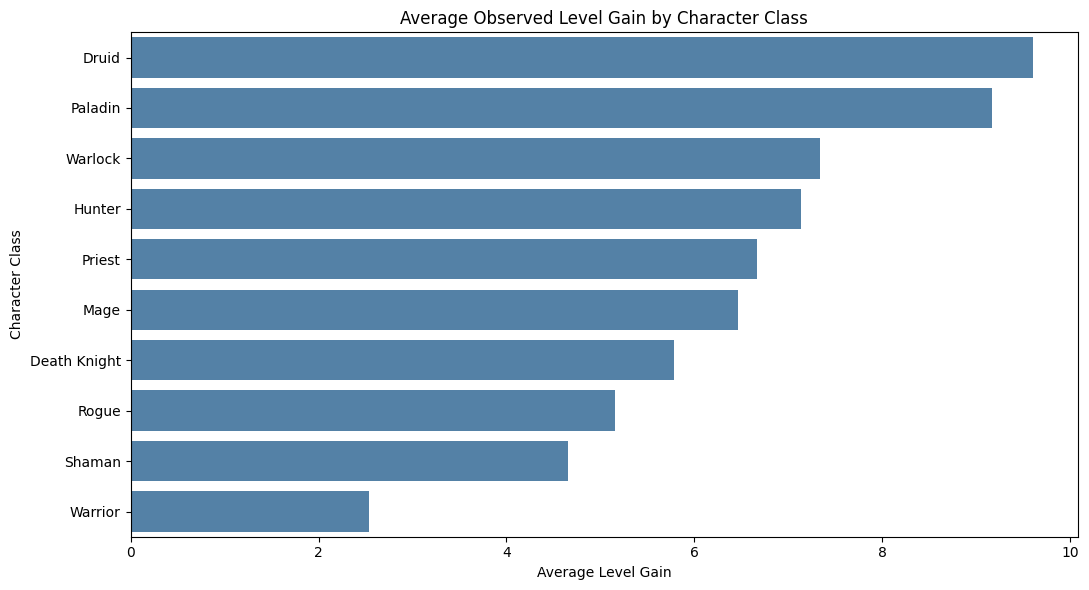

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=class_results,
    x='avg_level_gain',
    y='charclass',
    color='steelblue'
)

plt.title('Average Observed Level Gain by Character Class')
plt.xlabel('Average Level Gain')
plt.ylabel('Character Class')

plt.tight_layout()
plt.show()

### Interpretation: Character Class Progression

The analysis compares observed level progression across ten World of Warcraft character classes.

**Druids (9.60 levels)** and **Paladins (9.17 levels)** exhibited the highest average level gains between their first and last recorded observations.

In contrast, **Warriors (2.54 levels)** and **Shamans (4.65 levels)** showed the lowest average observed gains.

Death Knights had the highest proportion of characters showing positive level progression (73.90%), despite having the shortest average observation span (15.92 days).

These results indicate differences in observed progression patterns across character classes. However, the differences should not be interpreted as direct evidence that certain classes level faster or provide a better gameplay experience.

Factors such as starting level, observation duration, character creation timing, and level caps may influence these outcomes.

### Business Interpretation

The results suggest that character class is a useful dimension for segmenting progression behavior.

Warriors and Shamans could be investigated further to determine whether their relatively low observed progression is associated with shorter observation histories, higher starting levels, or other factors.

Additional analysis controlling for starting level and observation duration would be required before recommending class-specific game balance changes.

## Character Engagement & Return Activity Analysis

### Business Questions

- How frequently are characters observed on different days?
- What percentage of characters appear on multiple observation days?
- How does observed activity differ across character classes?
- Is repeated observed activity associated with higher character progression?

### Analytical Approach

The dataset contains repeated character observations recorded during 2008.

To measure observed engagement, I calculate the number of distinct observation dates for each character.

This approach avoids counting multiple observations on the same date as separate active days.

However, observations are not necessarily complete records of gameplay sessions. Therefore, these metrics represent **observed character activity**, rather than exact playtime, conventional daily active users, or confirmed player retention.

In [40]:
# Ensure column names are clean
df.columns = df.columns.str.strip()

# Ensure timestamps are datetime values
df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    errors='coerce'
)

# Create observation date
df['date'] = df['timestamp'].dt.date

# Count distinct observation dates per character
character_activity = (
    df.groupby('char')
    .agg(
        observed_days_count=('date', 'nunique'),
        total_observations=('date', 'size'),
        first_seen=('timestamp', 'min'),
        last_seen=('timestamp', 'max')
    )
    .reset_index()
)

print("Total characters:", len(character_activity))

display(character_activity.head())

print("\nActivity summary:")
display(
    character_activity[
        ['observed_days_count', 'total_observations']
    ].describe()
)

Total characters: 37354


,char,observed_days_count,total_observations,first_seen,last_seen
0,2,1,1,2008-12-03 10:41:47,2008-12-03 10:41:47
1,7,50,655,2008-01-15 21:47:09,2008-12-28 23:06:41
2,9,133,2739,2008-01-01 11:02:20,2008-06-29 21:13:52
3,10,49,674,2008-07-06 17:04:02,2008-11-07 20:33:59
4,19,149,3001,2008-01-07 03:01:19,2008-12-29 01:35:10



Activity summary:


,observed_days_count,total_observations
count,37354.000000,37354.000000
mean,18.510655,289.841356
std,44.083495,957.006915
min,1.000000,1.000000
25%,1.000000,2.000000
50%,2.000000,6.000000
75%,10.000000,59.000000
max,352.000000,42801.000000


In [41]:
# Add character activity to SQLite
character_activity.to_sql(
    'character_activity',
    conn,
    if_exists='replace',
    index=False
)

query_activity = """
SELECT
    COUNT(*) AS total_characters,

    ROUND(AVG(observed_days_count), 2)
        AS avg_observed_days,

    ROUND(AVG(total_observations), 2)
        AS avg_observations_per_character,

    SUM(
        CASE WHEN observed_days_count = 1
        THEN 1 ELSE 0 END
    ) AS one_day_characters,

    SUM(
        CASE WHEN observed_days_count > 1
        THEN 1 ELSE 0 END
    ) AS multiple_day_characters,

    ROUND(
        100.0 * SUM(
            CASE WHEN observed_days_count > 1
            THEN 1 ELSE 0 END
        ) / COUNT(*),
        2
    ) AS multiple_day_pct

FROM character_activity;
"""

activity_results = pd.read_sql_query(
    query_activity, conn
)

display(activity_results.T)

,0
total_characters,37354.00
avg_observed_days,18.51
avg_observations_per_character,289.84
one_day_characters,16259.00
multiple_day_characters,21095.00
multiple_day_pct,56.47


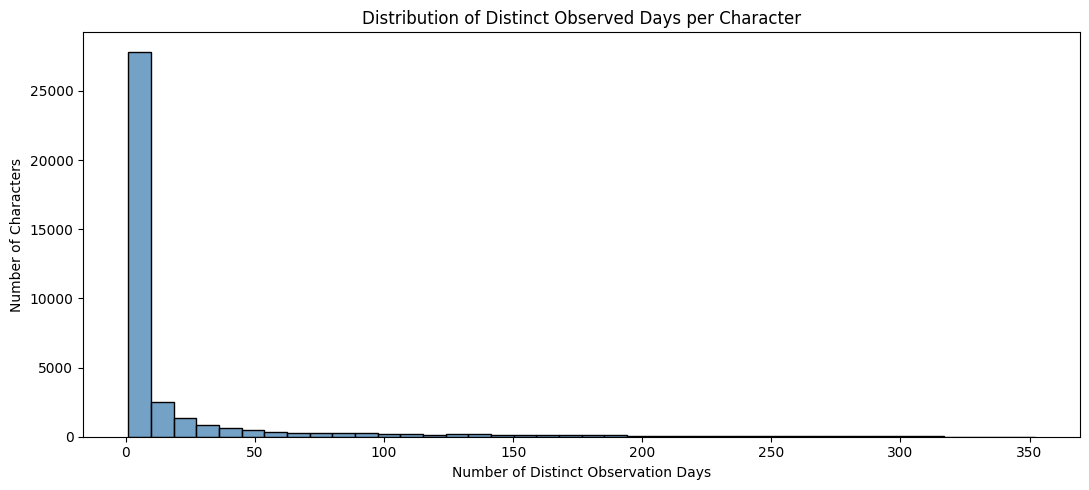

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 5))

sns.histplot(
    data=character_activity,
    x='observed_days_count',
    bins=40,
    color='steelblue'
)

plt.title('Distribution of Distinct Observed Days per Character')
plt.xlabel('Number of Distinct Observation Days')
plt.ylabel('Number of Characters')

plt.tight_layout()
plt.show()

In [43]:
# Combine progression and activity data
engagement_progression = progression.merge(
    character_activity[
        ['char', 'observed_days_count']
    ],
    on='char',
    how='inner',
    validate='one_to_one'
)

# Create observation frequency segments
engagement_progression['activity_segment'] = pd.cut(
    engagement_progression['observed_days_count'],
    bins=[0, 1, 5, 20, float('inf')],
    labels=[
        '1 day',
        '2–5 days',
        '6–20 days',
        '21+ days'
    ]
)

# Compare observed progression by segment
segment_results = (
    engagement_progression
    .groupby('activity_segment', observed=True)
    .agg(
        characters=('char', 'count'),
        avg_level_gain=('level_change', 'mean'),
        median_level_gain=('level_change', 'median'),
        avg_starting_level=('first_level', 'mean')
    )
    .round(2)
)

display(segment_results)

,characters,avg_level_gain,median_level_gain,avg_starting_level
activity_segment,,,,
1 day,16259,0.64,0.0,5.49
2–5 days,9193,3.22,1.0,10.46
6–20 days,5257,8.74,6.0,18.55
21+ days,6645,20.27,10.0,38.91


### Interpretation: Character Engagement and Progression

The analysis examined observed activity patterns among 37,354 unique World of Warcraft characters.

Approximately **56.47% of characters (21,095)** were recorded on more than one distinct date, while **43.53% (16,259)** appeared on only one date.

The distribution of observed activity is strongly right-skewed. Although the average character was recorded on 18.51 distinct days, the median was only 2 days, indicating that a smaller group of frequently observed characters contributes substantially to the overall average.

### Engagement and Level Progression

Characters observed on more distinct dates also demonstrated higher average level gains.

- **1 day:** 0.64 levels
- **2–5 days:** 3.22 levels
- **6–20 days:** 8.74 levels
- **21+ days:** 20.27 levels

The 21+ day group also had a substantially higher average starting level (38.91) than the one-day group (5.49).

These differences suggest an association between observation frequency and observed character progression.

However, the findings should not be interpreted as a causal relationship. Characters with longer observation histories have greater opportunities for recorded progression, and starting levels differ considerably across activity groups.

### Business Interpretation

The analysis highlights substantial variation in observed character activity and progression.

Further segmentation by starting level and observation history could help determine whether progression differences persist among more comparable character groups.

The results also demonstrate the importance of distinguishing observed activity from actual retention or gameplay duration when working with incomplete game telemetry.

## Progression Analysis by Starting Level

### Business Question

How does observed character progression differ across starting-level groups?

### Analytical Approach

Characters are segmented according to their first recorded level. Average and median level gains are compared across these groups, alongside observation frequency and observation span.

This analysis helps assess whether differences in progression are partly associated with characters' starting positions.

However, starting-level segmentation alone does not eliminate differences in observation histories, level caps, or character behavior.

In [44]:
# Create starting-level groups
engagement_progression['starting_level_group'] = pd.cut(
    engagement_progression['first_level'],
    bins=[0, 20, 40, 60, 80],
    labels=['1–20', '21–40', '41–60', '61–80'],
    include_lowest=True
)

# Summarize progression by starting level
starting_level_results = (
    engagement_progression
    .groupby('starting_level_group', observed=True)
    .agg(
        characters=('char', 'count'),
        avg_level_gain=('level_change', 'mean'),
        median_level_gain=('level_change', 'median'),
        avg_observed_days=('observed_days_count', 'mean'),
        avg_observation_span=('observed_days', 'mean')
    )
    .round(2)
)

display(starting_level_results)

,characters,avg_level_gain,median_level_gain,avg_observed_days,avg_observation_span
starting_level_group,,,,,
1–20,28647,6.01,0.0,8.17,42.61
21–40,2151,9.18,1.0,27.73,161.22
41–60,3247,6.16,3.0,23.44,91.07
61–80,3309,2.65,0.0,97.21,256.47


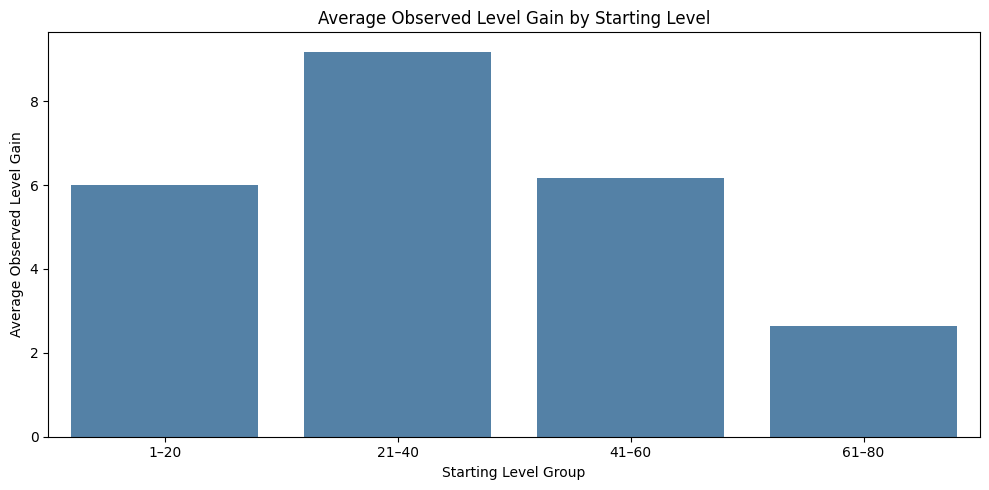

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=starting_level_results.reset_index(),
    x='starting_level_group',
    y='avg_level_gain',
    color='steelblue'
)

plt.title('Average Observed Level Gain by Starting Level')
plt.xlabel('Starting Level Group')
plt.ylabel('Average Observed Level Gain')

plt.tight_layout()
plt.show()

### Interpretation: Progression by Starting Level

The analysis compares observed character progression across four starting-level groups.

Characters starting at levels **21–40** demonstrated the highest average level gain (9.18 levels), followed by characters starting at levels 41–60 (6.16) and 1–20 (6.01).

Characters starting at levels **61–80** demonstrated the lowest average level gain (2.65), despite having the highest average number of distinct observation days (97.21).

The results also reveal differences in observation histories. Characters beginning at levels 21–40 had an average observation span of 161.22 days, compared with 42.61 days for the 1–20 group.

These differences suggest that observed level gains are influenced by both starting-level position and observation coverage.

The median level gain was zero for the 1–20 and 61–80 groups, indicating that at least half of the characters in these groups showed no net level increase during their observed histories.

### Business Interpretation

The results do not establish that progression is more difficult at higher levels.

Characters starting near level 80 have fewer opportunities to gain additional levels, while low-level characters may have shorter observation histories or represent alternate characters.

Therefore, comparing raw level gains alone can produce misleading conclusions.

Further analysis should examine progression within more comparable starting-level and observation-history groups before identifying potential gameplay bottlenecks.

In [46]:
# Compare progression by starting level AND activity segment

controlled_results = (
    engagement_progression
    .groupby(
        ['starting_level_group', 'activity_segment'],
        observed=True
    )
    .agg(
        characters=('char', 'count'),
        avg_level_gain=('level_change', 'mean'),
        median_level_gain=('level_change', 'median'),
        avg_observation_span=('observed_days', 'mean')
    )
    .round(2)
    .reset_index()
)

display(controlled_results)

,starting_level_group,activity_segment,characters,avg_level_gain,median_level_gain,avg_observation_span
0,1–20,1 day,15005,0.67,0.0,0.03
1,1–20,2–5 days,7614,3.70,2.0,37.65
2,1–20,6–20 days,3571,11.15,10.0,119.44
3,1–20,21+ days,2457,38.25,39.0,206.41
4,21–40,1 day,395,0.07,0.0,0.02
5,21–40,2–5 days,537,0.50,0.0,105.47
6,21–40,6–20 days,547,3.79,2.0,184.19
7,21–40,21+ days,672,25.85,27.0,281.84
8,41–60,1 day,754,0.28,0.0,0.04
9,41–60,2–5 days,847,1.37,1.0,45.05


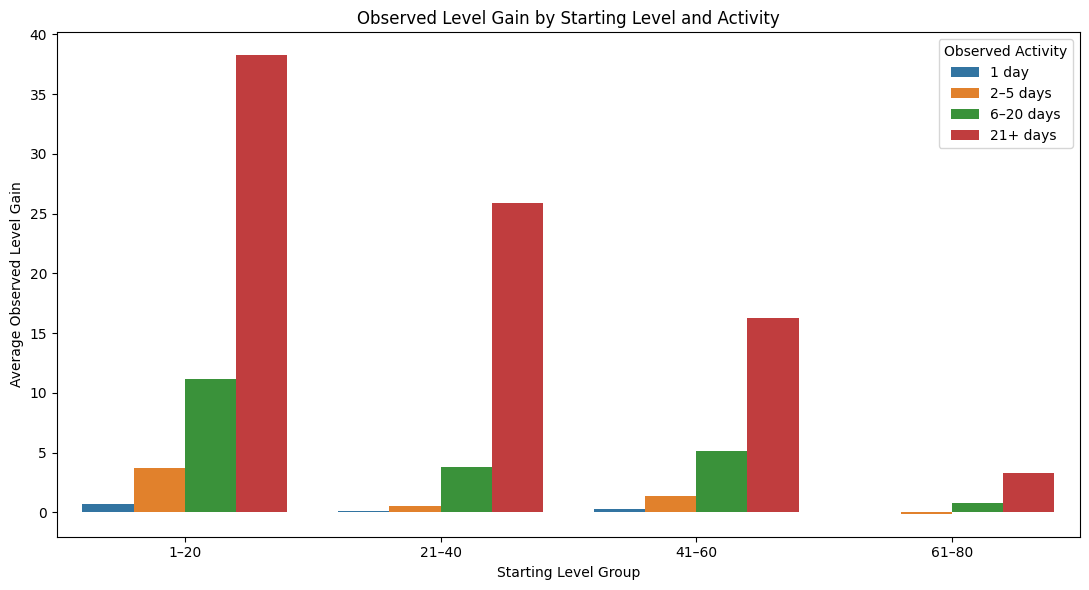

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=controlled_results,
    x='starting_level_group',
    y='avg_level_gain',
    hue='activity_segment'
)

plt.title('Observed Level Gain by Starting Level and Activity')
plt.xlabel('Starting Level Group')
plt.ylabel('Average Observed Level Gain')
plt.legend(title='Observed Activity')
plt.tight_layout()
plt.show()

### Interpretation: Starting Level and Observed Activity

The stratified analysis compared character progression across starting-level groups and observation-frequency segments.

Within every starting-level group, characters observed on 21 or more distinct dates showed the largest average level gains.

For characters starting at levels 1–20, average observed progression increased from 0.67 levels among characters observed on one day to 38.25 levels among characters observed on at least 21 days.

A similar pattern appeared across the other starting-level groups.

However, the activity segments also differed substantially in observation duration. Characters with longer observation histories had more opportunities for progression to occur and be recorded.

Among characters observed on at least 21 days, average level gains were lower in higher starting-level groups. This may partly reflect limited remaining leveling opportunities near the historical level cap.

One subgroup—characters starting at levels 61–80 and observed on 2–5 distinct days—showed a small negative average level change (−0.13), which warrants further data quality investigation.

### Business Interpretation

The findings demonstrate an association between observation frequency and recorded character progression, even after segmenting characters by starting level.

However, this analysis remains descriptive and does not establish that increased engagement causes faster progression.

Differences in observation duration, starting levels within brackets, character creation timing, and level-cap constraints remain potential sources of bias.

Before identifying progression bottlenecks or recommending gameplay balance changes, additional analysis of unexpected level decreases and more comparable character histories is needed.

In [48]:
# Investigate unexpected negative level changes

negative_progression = engagement_progression[
    engagement_progression['level_change'] < 0
]

print("Characters with negative level change:",
      len(negative_progression))

print("Percentage of all characters:",
      round(
          100 * len(negative_progression)
          / len(engagement_progression),
          2
      ))

print("\nLargest negative changes:")
display(
    negative_progression[
        ['char', 'first_level', 'last_level',
         'level_change', 'observed_days',
         'observed_days_count']
    ]
    .sort_values('level_change')
    .head(10)
)

print("\nNegative changes by starting-level group:")
display(
    negative_progression[
        'starting_level_group'
    ].value_counts().sort_index()
)

Characters with negative level change: 101
Percentage of all characters: 0.27

Largest negative changes:


,char,first_level,last_level,level_change,observed_days,observed_days_count
167,383,70,1,-69,360.275845,98
5329,27358,70,1,-69,118.466076,41
3450,22218,70,1,-69,283.051285,258
6400,32809,70,1,-69,207.090220,66
4592,24603,70,1,-69,283.572049,179
3309,21984,70,1,-69,321.472789,272
11309,62541,70,1,-69,261.323032,67
7522,38929,70,2,-68,160.151470,41
10737,60444,70,2,-68,72.837801,23
5652,28782,70,4,-66,263.859931,151



Negative changes by starting-level group:


starting_level_group
1–20     63
21–40    11
41–60     6
61–80    21
Name: count, dtype: int64

In [49]:

# Investigate selected characters with large negative changes
characters_to_check = [383, 27358, 22218]

history = (
    df.loc[
        df['char'].isin(characters_to_check),
        ['char', 'timestamp', 'level', 'race', 'charclass', 'zone']
    ]
    .sort_values(['char', 'timestamp'])
    .copy()
)

# Compare every level with the preceding observation
history['previous_level'] = (
    history.groupby('char')['level'].shift()
)

history['level_difference'] = (
    history['level'] - history['previous_level']
)

# Show only observations where a level decrease occurred
decreases = history[
    history['level_difference'] < 0
]

print("Recorded level decreases:")
display(decreases.head(20))

print("\nFirst and last observations:")
display(
    pd.concat([
        history.groupby('char').head(1),
        history.groupby('char').tail(1)
    ]).sort_values(['char', 'timestamp'])
)


Recorded level decreases:


,char,timestamp,level,race,charclass,zone,previous_level,level_difference
10756935,383,2008-12-29 00:41:47,1,Blood Elf,Mage,Eversong Woods,70.0,-69.0
8960953,22218,2008-10-09 01:37:39,1,Orc,Hunter,Durotar,70.0,-69.0
4611092,27358,2008-04-28 20:14:37,1,Blood Elf,Paladin,Eversong Woods,70.0,-69.0



First and last observations:


,char,timestamp,level,race,charclass,zone,previous_level,level_difference
102393,383,2008-01-03 18:04:34,70,Undead,Priest,Orgrimmar,NaN,NaN
10756935,383,2008-12-29 00:41:47,1,Blood Elf,Mage,Eversong Woods,70.0,-69.0
19219,22218,2008-01-01 13:52:22,70,Orc,Hunter,Shattrath City,NaN,NaN
8994633,22218,2008-10-10 15:06:13,1,Orc,Hunter,Orgrimmar,1.0,0.0
10368,27358,2008-01-01 09:14:25,70,Undead,Rogue,Warsong Gulch,NaN,NaN
4611577,27358,2008-04-28 20:25:34,1,Blood Elf,Paladin,Eversong Woods,1.0,0.0


### Data Quality Investigation: Negative Level Changes

The character progression analysis identified **101 characters (0.27%)** whose last recorded level was lower than their first recorded level.

The largest observed decrease was 69 levels. Several characters were recorded at level 70 initially and at level 1 or 2 in their final observations.

These changes are inconsistent with normal character leveling and may indicate character identifier reuse, data collection inconsistencies, or other recording anomalies.

Although negative net progression affects only a small proportion of characters, extreme decreases could influence summary statistics, especially within smaller character segments.

The next step is to examine chronological observation histories for selected characters and assess whether the anomalies materially affect the main progression findings.

No records have been excluded solely because they show negative progression.

### Interpretation: Investigation of Negative Level Changes

The chronological investigation revealed substantial inconsistencies in selected character histories.

Character 383 was initially observed as a level 70 Undead Priest and later as a level 1 Blood Elf Mage. Character 27358 similarly changed from a level 70 Undead Rogue to a level 1 Blood Elf Paladin.

Character 22218 experienced a decrease from level 70 to level 1 without an accompanying change in recorded race or class.

These findings suggest that some character identifiers may have been reused or that the records contain inconsistencies. The exact causes cannot be determined from the available dataset.

A total of 101 characters (0.27% of all unique character identifiers) exhibited negative net level changes.

**Data Quality Implication**

Treating all observations associated with a character identifier as one continuous progression history may produce misleading estimates.

A sensitivity analysis excluding identifiers with negative net progression will be performed to assess their influence on the overall results. Such exclusions will be treated as an analytical robustness check rather than definitive data cleaning.

The original dataset will remain available for comparison.

In [50]:

# Original character progression summary
original_summary = progression['level_change'].agg(
    ['count', 'mean', 'median']
)

# Exclude identifiers with negative net level change
progression_clean = progression[
    progression['level_change'] >= 0
].copy()

clean_summary = progression_clean['level_change'].agg(
    ['count', 'mean', 'median']
)

comparison = pd.DataFrame({
    'Original data': original_summary,
    'Without negative changes': clean_summary
})

print("Overall progression sensitivity analysis:")
display(comparison.round(2))

# Compare class-level average gains
original_class = (
    progression.groupby('charclass')['level_change']
    .mean()
)

clean_class = (
    progression_clean.groupby('charclass')['level_change']
    .mean()
)

class_comparison = pd.DataFrame({
    'Original avg gain': original_class,
    'Without negative changes': clean_class
})

class_comparison['difference'] = (
    class_comparison['Without negative changes']
    - class_comparison['Original avg gain']
)

print("\nClass-level sensitivity analysis:")
display(class_comparison.round(2))


Overall progression sensitivity analysis:


,Original data,Without negative changes
count,37354.00,37253.00
mean,5.91,5.97
median,0.00,0.00



Class-level sensitivity analysis:


,Original avg gain,Without negative changes,difference
charclass,,,
Death Knight,5.78,5.89,0.11
Druid,9.60,9.67,0.07
Hunter,7.13,7.20,0.06
Mage,6.46,6.52,0.07
Paladin,9.17,9.27,0.10
Priest,6.66,6.77,0.10
Rogue,5.15,5.21,0.07
Shaman,4.65,4.71,0.06
Warlock,7.34,7.37,0.04


### Interpretation: Progression Sensitivity Analysis

A sensitivity analysis was conducted to assess whether character identifiers with negative net level changes materially influenced the progression results.

The original analysis included **37,354 character identifiers**, with an average observed level gain of **5.91** and a median gain of **0**.

After excluding the 101 identifiers with negative net changes, the sample contained **37,253 identifiers**. The average observed level gain increased slightly to **5.97**, while the median remained unchanged at **0**.

At the character-class level, excluding these identifiers produced only minor changes in average observed progression. The overall class rankings remained stable, with Druids and Paladins showing the highest average gains and Warriors showing the lowest.

### Business Interpretation

The main descriptive progression findings appear robust to excluding identifiers with negative net level changes.

However, the analysis does not identify all potential character-identifier inconsistencies. Some identifiers may represent multiple characters without showing negative net progression.

Therefore, the original results should be interpreted as observed character-identifier patterns rather than definitive player-level progression measures.

The sensitivity analysis strengthens confidence that the 101 negative-change identifiers are not the primary drivers of the reported average progression differences.

## Final Business Insights & Recommendations

### Project Objective

This project analyzed historical World of Warcraft character observations from 2008 to investigate level progression, character activity, and differences across character classes.

The objective was to identify descriptive patterns that could inform future game design and player engagement investigations.

### Key Findings

**1. Character Progression**

Across 37,354 character identifiers, the average observed level change was 5.91 levels, while the median was 0.

Approximately 48.2% of characters showed positive net progression between their first and last observations.

**2. Character Class Differences**

Druids and Paladins demonstrated the highest average observed level gains (9.60 and 9.17 levels, respectively).

Warriors had the lowest average observed gain (2.54 levels).

These differences may reflect starting levels, character behavior, observation duration, and progression opportunities rather than class-specific leveling difficulty.

**3. Observed Character Activity**

Approximately 56.47% of characters were recorded on more than one distinct observation date.

The median number of observed days was 2, while the mean was 18.51, demonstrating a highly right-skewed activity distribution.

**4. Engagement and Progression**

Characters observed on more distinct dates generally showed larger observed level gains.

However, this association does not establish a causal relationship because observation duration and starting levels differ across groups.

**5. Data Quality and Robustness**

The analysis identified 101 character identifiers with negative net level changes.

Excluding those identifiers increased the overall average level gain from 5.91 to 5.97, while the median remained unchanged.

This suggests that the main descriptive progression findings are not substantially driven by these particular anomalies.

### Business Recommendations

**1. Investigate early-level character activity**

Many characters were observed only at low levels or on a limited number of dates. Further investigation could examine whether these patterns reflect newly created characters, alternate characters, limited data coverage, or potential early-stage engagement issues.

**2. Segment progression analysis by character characteristics**

Starting level, class, and observation duration should be considered when comparing progression patterns. Raw level gains alone are insufficient to determine leveling difficulty.

**3. Improve character-level tracking**

Consistent character identifiers and more complete gameplay event data would allow progression, session activity, and player return behavior to be measured more reliably.

**4. Investigate class-level progression differences**

The lower average observed gains for Warriors and Shamans could be investigated using more comparable observation histories and starting-level groups before considering any game balance changes.

### Limitations

- The dataset represents historical observations from 2008 and may not reflect current World of Warcraft gameplay.
- Character identifiers do not necessarily correspond to unique players.
- Observations do not provide exact gameplay duration or complete session histories.
- Some character identifiers exhibit inconsistent progression and character attributes.
- Correlations between observed activity and progression do not demonstrate causation.
- Historical level caps limit the comparability of raw level gains across starting levels.

### Final Takeaway

**Player progression analysis requires more than comparing average levels.**

Meaningful game analytics must account for character starting points, observation histories, data quality, and progression constraints before translating descriptive patterns into product recommendations.

This project demonstrates how Python, SQL, data visualization, segmentation, and sensitivity analysis can support evidence-based game analytics.